<a href="https://colab.research.google.com/github/mariaalshuttary14-ai/MyLabN/blob/main/kmeans_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install numpy matplotlib scikit-learn scikit-image

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from skimage import data

In [ ]:
X, y = make_blobs(
    n_samples=1000,
    centers=4,
    random_state=42
)

print("Dataset shape:", X.shape)


Dataset shape: (1000, 2)


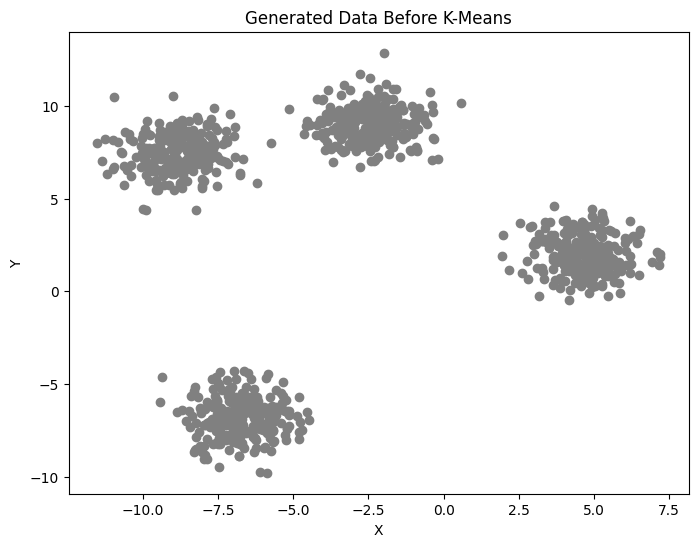

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(X[:, 0], X[:, 1], color="gray")

plt.title("Generated Data Before K-Means")
plt.xlabel("X")
plt.ylabel("Y")

plt.savefig("kmeans_data_before.png")
plt.show()

In [ ]:

# Create the K-Means model with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# Assign each point to a cluster
labels = kmeans.fit_predict(X)

# Display the cluster centers
print("Cluster centers:")
print(kmeans.cluster_centers_)


Cluster centers:
[[-2.50173875  9.03287546]
 [-6.74543497 -6.81351756]
 [ 4.65760511  2.0269603 ]
 [-8.85662684  7.41339818]]


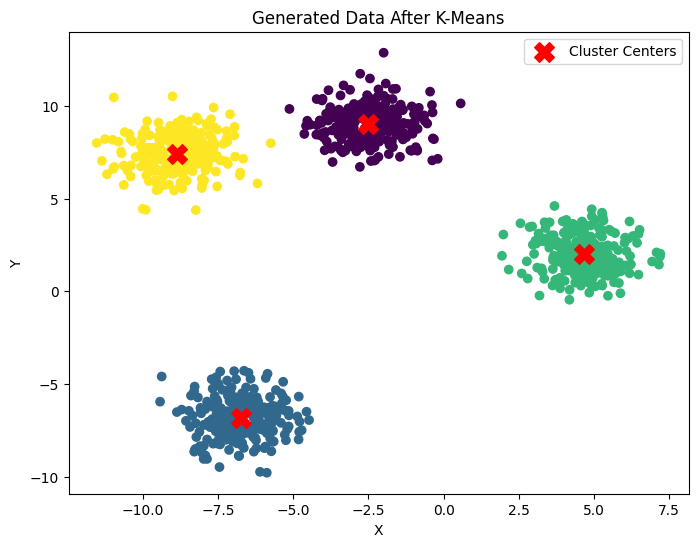

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis"
)

# Mark the cluster centers with red X markers
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Cluster Centers"
)

plt.title("Generated Data After K-Means")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()

plt.savefig("kmeans_data_after.png")
plt.show()

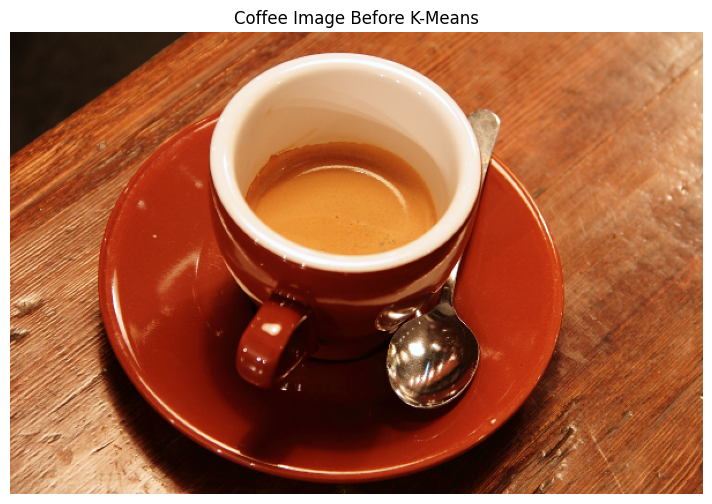

In [ ]:
coffee = data.coffee()

plt.figure(figsize=(10, 6))
plt.imshow(coffee)
plt.title("Coffee Image Before K-Means")
plt.axis("off")

plt.savefig("kmeans_image_before.png")
plt.show()

In [ ]:
height, width, channels = coffee.shape

pixels = coffee.reshape(-1, 3)

image_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

pixel_labels = image_kmeans.fit_predict(pixels)

clustered_pixels = image_kmeans.cluster_centers_[pixel_labels]


clustered_image = clustered_pixels.reshape(height, width, 3)


clustered_image = np.clip(clustered_image, 0, 255).astype(np.uint8)

print("Original image shape:", coffee.shape)
print("Reshaped pixels:", pixels.shape)
print("Clustered image shape:", clustered_image.shape)


Original image shape: (400, 600, 3)
Reshaped pixels: (240000, 3)
Clustered image shape: (400, 600, 3)


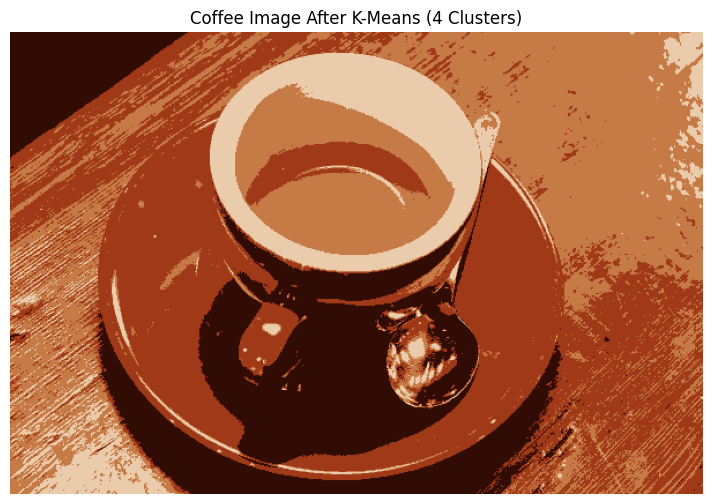

In [ ]:
plt.figure(figsize=(10, 6))

plt.imshow(clustered_image)
plt.title("Coffee Image After K-Means (4 Clusters)")
plt.axis("off")

plt.savefig("kmeans_image_after.png")
plt.show()